# Notebook 04 — Model Baseline

**Đề tài:** Nghiên cứu xây dựng mô hình Machine Learning trong đánh giá và dự báo rủi ro tín dụng khách hàng  
**Sinh viên:** Nguyễn Trọng Thể — MSSV: 1150080117  
**Giai đoạn:** Tuần 6 — Baseline Machine Learning

---

## Mục tiêu
Huấn luyện và đánh giá 4 cấu hình baseline:
1. Logistic Regression — default  
2. Logistic Regression — `class_weight='balanced'`  
3. Decision Tree — default  
4. Decision Tree — `class_weight='balanced'`  

**Chưa thực hiện:** Random Forest, XGBoost, SMOTE, GridSearch, Optuna, SHAP, Streamlit.

## 1. Introduction

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve,
    classification_report
)

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

# Thư mục gốc của project
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_DIR     = os.path.join(PROJECT_ROOT, 'data', 'processed')
FIGURES_DIR  = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR   = os.path.join(PROJECT_ROOT, 'models')
REPORTS_DIR  = os.path.join(PROJECT_ROOT, 'reports')

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,  exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Data dir:    ', DATA_DIR)
print('Figures dir: ', FIGURES_DIR)

Project root: f:\DATN\project
Data dir:     f:\DATN\project\data\processed
Figures dir:  f:\DATN\project\reports\figures


## 2. Load Data

In [2]:
X_train = pd.read_csv(os.path.join(DATA_DIR, 'X_train_fe.csv'))
X_test  = pd.read_csv(os.path.join(DATA_DIR, 'X_test_fe.csv'))
y_train_df = pd.read_csv(os.path.join(DATA_DIR, 'y_train.csv'))
y_test_df  = pd.read_csv(os.path.join(DATA_DIR, 'y_test.csv'))

TARGET_COL = y_train_df.columns[0]
y_train = y_train_df[TARGET_COL]
y_test  = y_test_df[TARGET_COL]

print(f'Target column: {TARGET_COL}')
print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')
print(f'y_train : {y_train.shape}')
print(f'y_test  : {y_test.shape}')

Target column: default.payment.next.month
X_train : (23972, 33)
X_test  : (5993, 33)
y_train : (23972,)
y_test  : (5993,)


## 3. Input Validation

In [3]:
print('=' * 50)
print('FINAL ML INPUT VALIDATION')
print('=' * 50)

def check(label, passed, detail=''):
    status = 'PASS' if passed else 'FAIL'
    msg = f'  [{status}] {label}'
    if detail:
        msg += f'  ({detail})'
    print(msg)
    return passed

results = []
results.append(check('X_train loaded', True))
results.append(check('X_test loaded',  True))

# Target not in features
results.append(check('Target exclusion',
    TARGET_COL not in X_train.columns and TARGET_COL not in X_test.columns))

# ID exclusion
results.append(check('ID exclusion',
    not any(c in X_train.columns for c in ['ID', 'id'])))

# NaN
nan_tr = X_train.isna().sum().sum()
nan_te = X_test.isna().sum().sum()
results.append(check('NaN check', nan_tr + nan_te == 0, f'train={nan_tr}, test={nan_te}'))

# Inf
inf_tr = np.isinf(X_train.select_dtypes(include=np.number)).sum().sum()
inf_te = np.isinf(X_test.select_dtypes(include=np.number)).sum().sum()
results.append(check('Inf check', inf_tr + inf_te == 0, f'train={inf_tr}, test={inf_te}'))

# Feature consistency
same_cols = list(X_train.columns) == list(X_test.columns)
results.append(check('Feature consistency (same columns & order)', same_cols))

# y schema
y_ok = set(y_train.unique()).issubset({0, 1}) and set(y_test.unique()).issubset({0, 1})
results.append(check('y schema (binary {0,1})', y_ok))

print()
print('[ALL PASS]' if all(results) else '[SOME FAIL — xem chi tiết]')

FINAL ML INPUT VALIDATION
  [PASS] X_train loaded
  [PASS] X_test loaded
  [PASS] Target exclusion
  [PASS] ID exclusion
  [PASS] NaN check  (train=0, test=0)
  [PASS] Inf check  (train=0, test=0)
  [PASS] Feature consistency (same columns & order)
  [PASS] y schema (binary {0,1})

[ALL PASS]


## 4. Class Distribution

=== CLASS DISTRIBUTION ===

Train set:
  Class 0 (Non-default): 18,668  (77.87%)
  Class 1 (Default): 5,304  (22.13%)

Test set:
  Class 0 (Non-default): 4,667  (77.87%)
  Class 1 (Default): 1,326  (22.13%)

Imbalance ratio (0:1) = 3.52:1


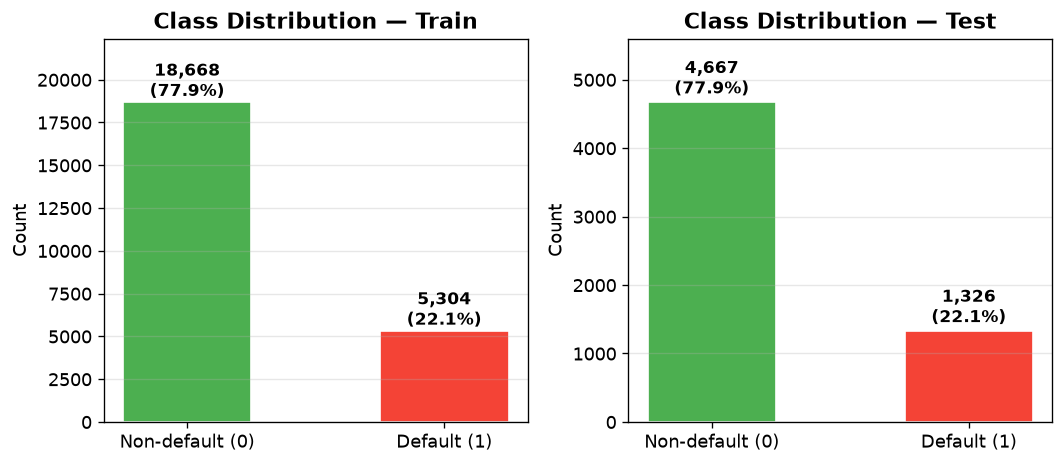

Saved: f:\DATN\project\reports\figures\class_distribution.png


In [4]:
print('=== CLASS DISTRIBUTION ===')
tr_counts = y_train.value_counts().sort_index()
te_counts = y_test.value_counts().sort_index()

print('\nTrain set:')
for cls, cnt in tr_counts.items():
    lbl = 'Non-default' if cls == 0 else 'Default'
    print(f'  Class {cls} ({lbl}): {cnt:,}  ({cnt/len(y_train)*100:.2f}%)')

print('\nTest set:')
for cls, cnt in te_counts.items():
    lbl = 'Non-default' if cls == 0 else 'Default'
    print(f'  Class {cls} ({lbl}): {cnt:,}  ({cnt/len(y_test)*100:.2f}%)')

imbalance_ratio = tr_counts[0] / tr_counts[1]
print(f'\nImbalance ratio (0:1) = {imbalance_ratio:.2f}:1')

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
colors = ['#4CAF50', '#F44336']

for ax, (counts, title) in zip(axes, [(tr_counts, 'Train'), (te_counts, 'Test')]):
    labels = ['Non-default (0)', 'Default (1)']
    bars = ax.bar(labels, counts.values, color=colors, edgecolor='white', width=0.5)
    ax.set_title(f'Class Distribution — {title}', fontweight='bold')
    ax.set_ylabel('Count')
    total = counts.sum()
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                f'{val:,}\n({val/total*100:.1f}%)',
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylim(0, max(counts.values) * 1.2)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'class_distribution.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')

## 5. Logistic Regression Baseline

In [5]:
print('=== MODEL 1: Logistic Regression (Default) ===')

lr_default = LogisticRegression(max_iter=1000, random_state=42)
lr_default.fit(X_train, y_train)   # Fit CHỈ trên train

y_pred_lr   = lr_default.predict(X_test)
y_prob_lr   = lr_default.predict_proba(X_test)[:, 1]

print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr, target_names=['Non-default', 'Default']))

lr_acc  = accuracy_score(y_test, y_pred_lr)
lr_prec = precision_score(y_test, y_pred_lr, zero_division=0)
lr_rec  = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1   = f1_score(y_test, y_pred_lr, zero_division=0)
lr_roc  = roc_auc_score(y_test, y_prob_lr)
lr_pr   = average_precision_score(y_test, y_prob_lr)

print(f'Accuracy  = {lr_acc:.4f}')
print(f'Precision = {lr_prec:.4f}')
print(f'Recall    = {lr_rec:.4f}')
print(f'F1-Score  = {lr_f1:.4f}')
print(f'ROC-AUC   = {lr_roc:.4f}')
print(f'PR-AUC    = {lr_pr:.4f}')

=== MODEL 1: Logistic Regression (Default) ===

Classification Report:
              precision    recall  f1-score   support

 Non-default       0.83      0.96      0.89      4667
     Default       0.66      0.30      0.41      1326

    accuracy                           0.81      5993
   macro avg       0.74      0.63      0.65      5993
weighted avg       0.79      0.81      0.78      5993

Accuracy  = 0.8106
Precision = 0.6610
Recall    = 0.2956
F1-Score  = 0.4085
ROC-AUC   = 0.7492
PR-AUC    = 0.5162


## 6. Logistic Regression Balanced

In [6]:
print("=== MODEL 2: Logistic Regression (class_weight='balanced') ===")

lr_balanced = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_balanced.fit(X_train, y_train)

y_pred_lr_b = lr_balanced.predict(X_test)
y_prob_lr_b = lr_balanced.predict_proba(X_test)[:, 1]

print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr_b, target_names=['Non-default', 'Default']))

lrb_acc  = accuracy_score(y_test, y_pred_lr_b)
lrb_prec = precision_score(y_test, y_pred_lr_b, zero_division=0)
lrb_rec  = recall_score(y_test, y_pred_lr_b, zero_division=0)
lrb_f1   = f1_score(y_test, y_pred_lr_b, zero_division=0)
lrb_roc  = roc_auc_score(y_test, y_prob_lr_b)
lrb_pr   = average_precision_score(y_test, y_prob_lr_b)

print(f'Accuracy  = {lrb_acc:.4f}')
print(f'Precision = {lrb_prec:.4f}')
print(f'Recall    = {lrb_rec:.4f}')
print(f'F1-Score  = {lrb_f1:.4f}')
print(f'ROC-AUC   = {lrb_roc:.4f}')
print(f'PR-AUC    = {lrb_pr:.4f}')

=== MODEL 2: Logistic Regression (class_weight='balanced') ===

Classification Report:
              precision    recall  f1-score   support

 Non-default       0.87      0.79      0.83      4667
     Default       0.45      0.60      0.51      1326

    accuracy                           0.75      5993
   macro avg       0.66      0.69      0.67      5993
weighted avg       0.78      0.75      0.76      5993

Accuracy  = 0.7469
Precision = 0.4466
Recall    = 0.6018
F1-Score  = 0.5127
ROC-AUC   = 0.7514
PR-AUC    = 0.5123


## 7. Decision Tree Baseline

In [7]:
print('=== MODEL 3: Decision Tree (Default) ===')

dt_default = DecisionTreeClassifier(random_state=42)
dt_default.fit(X_train, y_train)

y_pred_dt  = dt_default.predict(X_test)
y_prob_dt  = dt_default.predict_proba(X_test)[:, 1]

print('\nClassification Report:')
print(classification_report(y_test, y_pred_dt, target_names=['Non-default', 'Default']))

dt_acc  = accuracy_score(y_test, y_pred_dt)
dt_prec = precision_score(y_test, y_pred_dt, zero_division=0)
dt_rec  = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1   = f1_score(y_test, y_pred_dt, zero_division=0)
dt_roc  = roc_auc_score(y_test, y_prob_dt)
dt_pr   = average_precision_score(y_test, y_prob_dt)

print(f'Accuracy  = {dt_acc:.4f}')
print(f'Precision = {dt_prec:.4f}')
print(f'Recall    = {dt_rec:.4f}')
print(f'F1-Score  = {dt_f1:.4f}')
print(f'ROC-AUC   = {dt_roc:.4f}')
print(f'PR-AUC    = {dt_pr:.4f}')

=== MODEL 3: Decision Tree (Default) ===

Classification Report:
              precision    recall  f1-score   support

 Non-default       0.83      0.82      0.82      4667
     Default       0.39      0.41      0.40      1326

    accuracy                           0.73      5993
   macro avg       0.61      0.61      0.61      5993
weighted avg       0.73      0.73      0.73      5993

Accuracy  = 0.7267
Precision = 0.3884
Recall    = 0.4095
F1-Score  = 0.3987
ROC-AUC   = 0.6130
PR-AUC    = 0.2897


## 8. Decision Tree Balanced

In [8]:
print("=== MODEL 4: Decision Tree (class_weight='balanced') ===")

dt_balanced = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt_balanced.fit(X_train, y_train)

y_pred_dt_b = dt_balanced.predict(X_test)
y_prob_dt_b = dt_balanced.predict_proba(X_test)[:, 1]

print('\nClassification Report:')
print(classification_report(y_test, y_pred_dt_b, target_names=['Non-default', 'Default']))

dtb_acc  = accuracy_score(y_test, y_pred_dt_b)
dtb_prec = precision_score(y_test, y_pred_dt_b, zero_division=0)
dtb_rec  = recall_score(y_test, y_pred_dt_b, zero_division=0)
dtb_f1   = f1_score(y_test, y_pred_dt_b, zero_division=0)
dtb_roc  = roc_auc_score(y_test, y_prob_dt_b)
dtb_pr   = average_precision_score(y_test, y_prob_dt_b)

print(f'Accuracy  = {dtb_acc:.4f}')
print(f'Precision = {dtb_prec:.4f}')
print(f'Recall    = {dtb_rec:.4f}')
print(f'F1-Score  = {dtb_f1:.4f}')
print(f'ROC-AUC   = {dtb_roc:.4f}')
print(f'PR-AUC    = {dtb_pr:.4f}')

=== MODEL 4: Decision Tree (class_weight='balanced') ===

Classification Report:
              precision    recall  f1-score   support

 Non-default       0.82      0.83      0.82      4667
     Default       0.38      0.37      0.37      1326

    accuracy                           0.73      5993
   macro avg       0.60      0.60      0.60      5993
weighted avg       0.72      0.73      0.73      5993

Accuracy  = 0.7262
Precision = 0.3784
Recall    = 0.3695
F1-Score  = 0.3739
ROC-AUC   = 0.5986
PR-AUC    = 0.2796


## 9. Metrics — Bảng tổng hợp

In [9]:
all_metrics = [
    {'Model': 'Logistic Regression (Default)',
     'Accuracy': lr_acc,  'Precision': lr_prec,  'Recall': lr_rec,
     'F1': lr_f1,         'ROC-AUC':  lr_roc,    'PR-AUC': lr_pr},
    {'Model': 'Logistic Regression (Balanced)',
     'Accuracy': lrb_acc, 'Precision': lrb_prec, 'Recall': lrb_rec,
     'F1': lrb_f1,        'ROC-AUC':  lrb_roc,   'PR-AUC': lrb_pr},
    {'Model': 'Decision Tree (Default)',
     'Accuracy': dt_acc,  'Precision': dt_prec,  'Recall': dt_rec,
     'F1': dt_f1,         'ROC-AUC':  dt_roc,    'PR-AUC': dt_pr},
    {'Model': 'Decision Tree (Balanced)',
     'Accuracy': dtb_acc, 'Precision': dtb_prec, 'Recall': dtb_rec,
     'F1': dtb_f1,        'ROC-AUC':  dtb_roc,   'PR-AUC': dtb_pr},
]

df_metrics = pd.DataFrame(all_metrics)
df_metrics_display = df_metrics.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    df_metrics_display[col] = df_metrics_display[col].map('{:.4f}'.format)

print(df_metrics_display.to_string(index=False))

                         Model Accuracy Precision Recall     F1 ROC-AUC PR-AUC
 Logistic Regression (Default)   0.8106    0.6610 0.2956 0.4085  0.7492 0.5162
Logistic Regression (Balanced)   0.7469    0.4466 0.6018 0.5127  0.7514 0.5123
       Decision Tree (Default)   0.7267    0.3884 0.4095 0.3987  0.6130 0.2897
      Decision Tree (Balanced)   0.7262    0.3784 0.3695 0.3739  0.5986 0.2796


## 10. Confusion Matrix

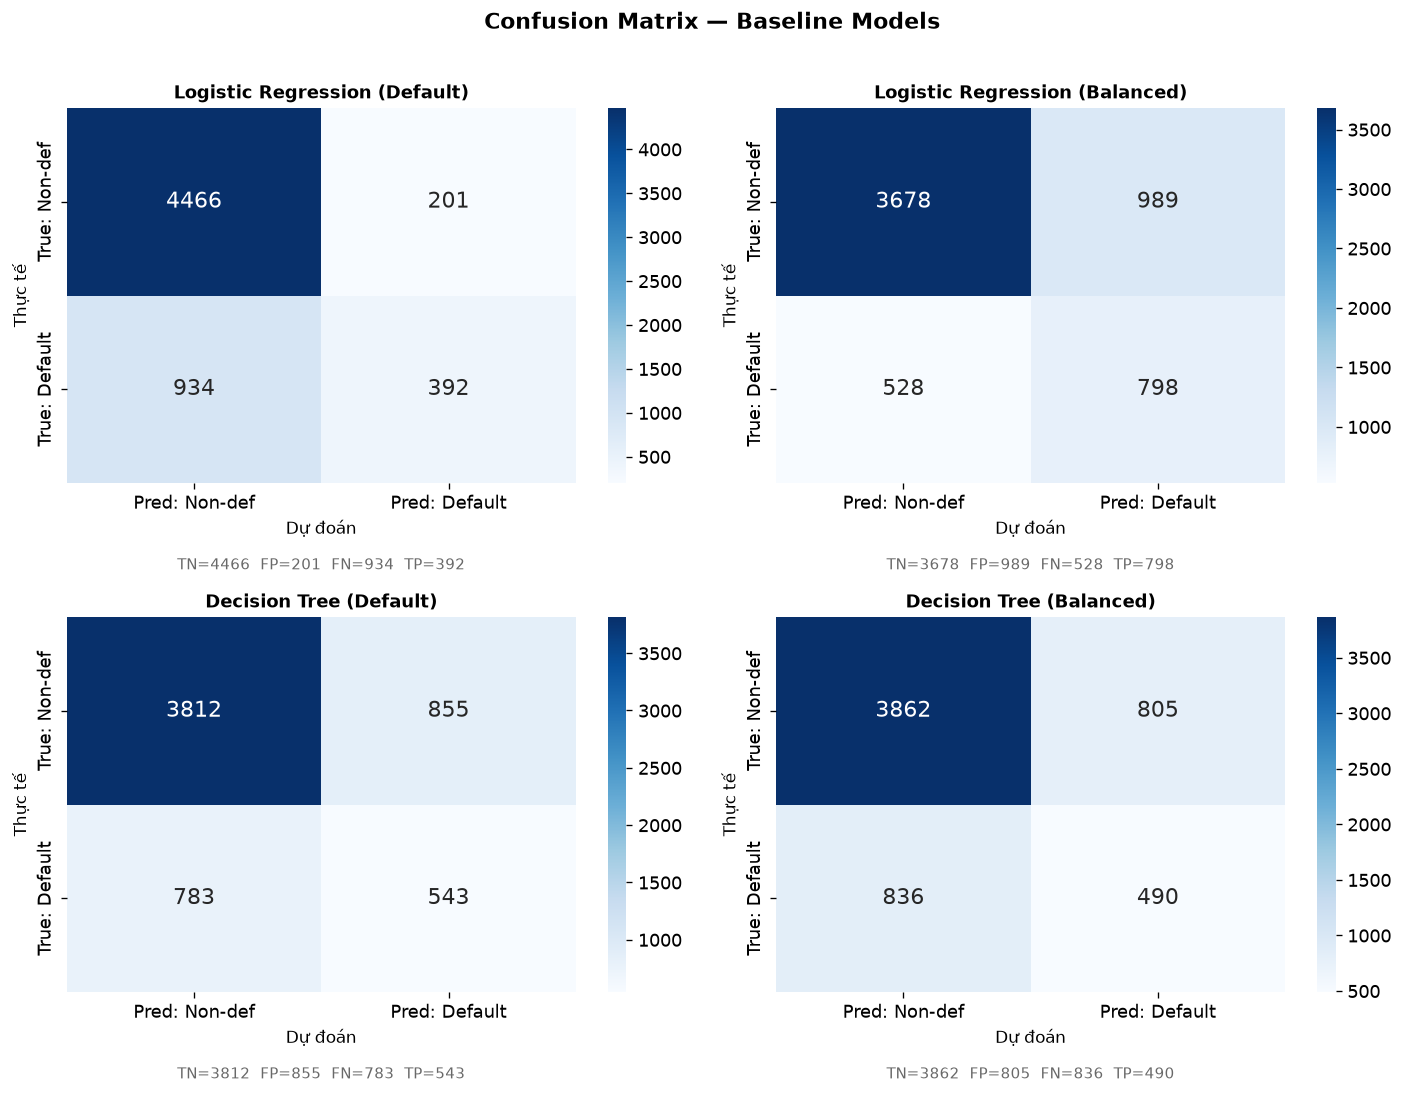

Saved: f:\DATN\project\reports\figures\confusion_matrix_all.png

--- Confusion Matrix breakdown ---
Model                                        TN     FP     FN     TP
-----------------------------------------------------------------
Logistic Regression (Default)              4466    201    934    392
Logistic Regression (Balanced)             3678    989    528    798
Decision Tree (Default)                    3812    855    783    543
Decision Tree (Balanced)                   3862    805    836    490

Ý nghĩa nghiệp vụ:
  FP = Khách hàng tốt bị từ chối sai (chi phí thấp hơn)
  FN = Khách hàng rủi ro được chấp nhận sai (chi phí cao hơn cho ngân hàng)


In [10]:
configs = [
    ('Logistic Regression (Default)',  y_pred_lr,   'confusion_logistic.png'),
    ('Logistic Regression (Balanced)', y_pred_lr_b, 'confusion_logistic_balanced.png'),
    ('Decision Tree (Default)',         y_pred_dt,   'confusion_tree.png'),
    ('Decision Tree (Balanced)',        y_pred_dt_b, 'confusion_tree_balanced.png'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, (title, y_pred, fname) in zip(axes, configs):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: Non-def', 'Pred: Default'],
                yticklabels=['True: Non-def', 'True: Default'],
                annot_kws={'size': 13})
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('Thực tế', fontsize=10)
    ax.set_xlabel('Dự đoán', fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    ax.text(0.5, -0.22, f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
            ha='center', va='center', transform=ax.transAxes,
            fontsize=9, color='dimgray')

plt.suptitle('Confusion Matrix — Baseline Models', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'confusion_matrix_all.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')

print('\n--- Confusion Matrix breakdown ---')
print(f'{"Model":<40} {"TN":>6} {"FP":>6} {"FN":>6} {"TP":>6}')
print('-' * 65)
for title, y_pred, _ in configs:
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f'{title:<40} {tn:>6} {fp:>6} {fn:>6} {tp:>6}')

print('\nÝ nghĩa nghiệp vụ:')
print('  FP = Khách hàng tốt bị từ chối sai (chi phí thấp hơn)')
print('  FN = Khách hàng rủi ro được chấp nhận sai (chi phí cao hơn cho ngân hàng)')

## 11. ROC Curve

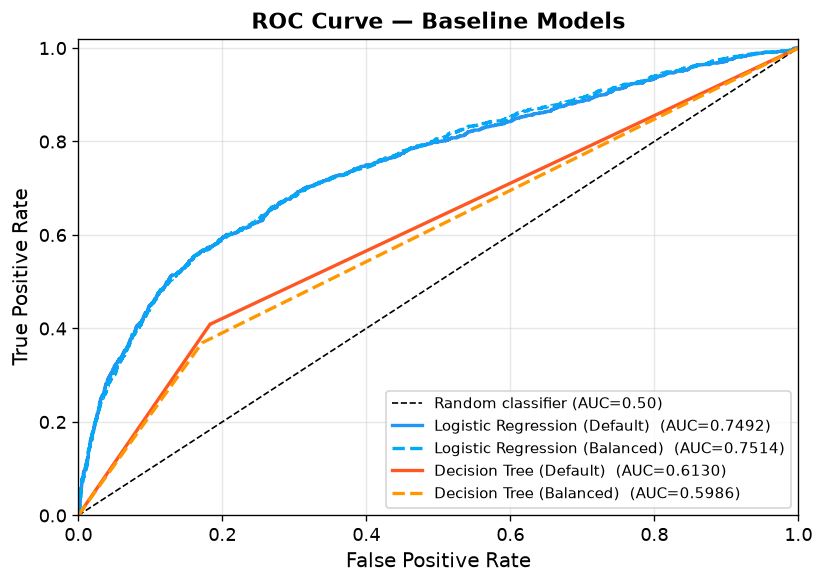

Saved: f:\DATN\project\reports\figures\baseline_roc_curve.png


In [11]:
models_info = [
    ('Logistic Regression (Default)',  y_prob_lr,   lr_roc,  '#2196F3', '-'),
    ('Logistic Regression (Balanced)', y_prob_lr_b, lrb_roc, '#03A9F4', '--'),
    ('Decision Tree (Default)',         y_prob_dt,   dt_roc,  '#FF5722', '-'),
    ('Decision Tree (Balanced)',        y_prob_dt_b, dtb_roc, '#FF9800', '--'),
]

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random classifier (AUC=0.50)')

for name, y_prob, auc_val, color, ls in models_info:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, color=color, linestyle=ls, lw=2,
            label=f'{name}  (AUC={auc_val:.4f})')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curve — Baseline Models', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'baseline_roc_curve.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')

## 12. Precision-Recall Curve

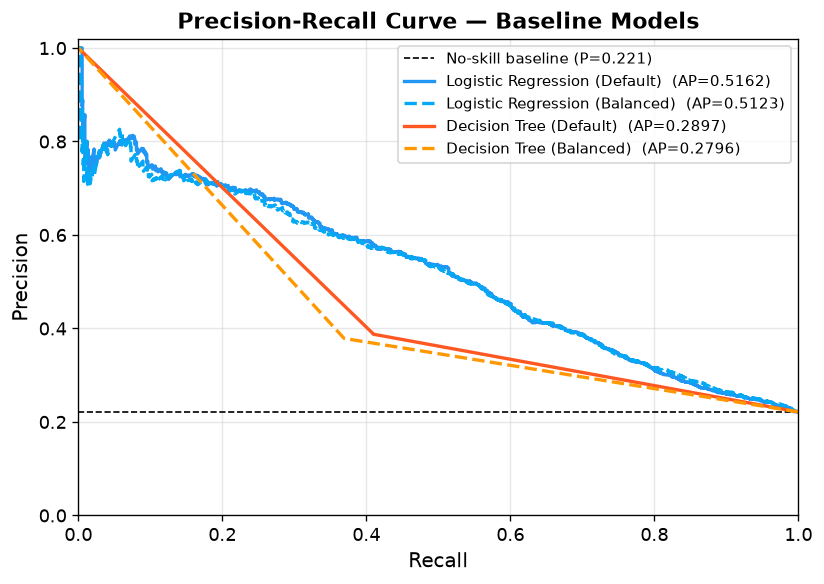

Saved: f:\DATN\project\reports\figures\baseline_pr_curve.png


In [12]:
baseline_p = y_test.mean()

fig, ax = plt.subplots(figsize=(7, 5))
ax.axhline(y=baseline_p, color='k', linestyle='--', lw=1,
           label=f'No-skill baseline (P={baseline_p:.3f})')

for name, y_prob, pr_val, color, ls in [
    ('Logistic Regression (Default)',  y_prob_lr,   lr_pr,  '#2196F3', '-'),
    ('Logistic Regression (Balanced)', y_prob_lr_b, lrb_pr, '#03A9F4', '--'),
    ('Decision Tree (Default)',         y_prob_dt,   dt_pr,  '#FF5722', '-'),
    ('Decision Tree (Balanced)',        y_prob_dt_b, dtb_pr, '#FF9800', '--'),
]:
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ax.plot(recall, precision, color=color, linestyle=ls, lw=2,
            label=f'{name}  (AP={pr_val:.4f})')

ax.set_xlabel('Recall', fontsize=12)
ax.set_ylabel('Precision', fontsize=12)
ax.set_title('Precision-Recall Curve — Baseline Models', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'baseline_pr_curve.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')

## 13. Model Comparison

=== BẢNG SO SÁNH TỔNG HỢP ===

Model                                       Accuracy Precision  Recall      F1   ROC-AUC   PR-AUC
----------------------------------------------------------------------------------------------------
Logistic Regression (Default)                 0.8106    0.6610  0.2956  0.4085    0.7492   0.5162
Logistic Regression (Balanced)                0.7469    0.4466  0.6018  0.5127    0.7514   0.5123
Decision Tree (Default)                       0.7267    0.3884  0.4095  0.3987    0.6130   0.2897
Decision Tree (Balanced)                      0.7262    0.3784  0.3695  0.3739    0.5986   0.2796


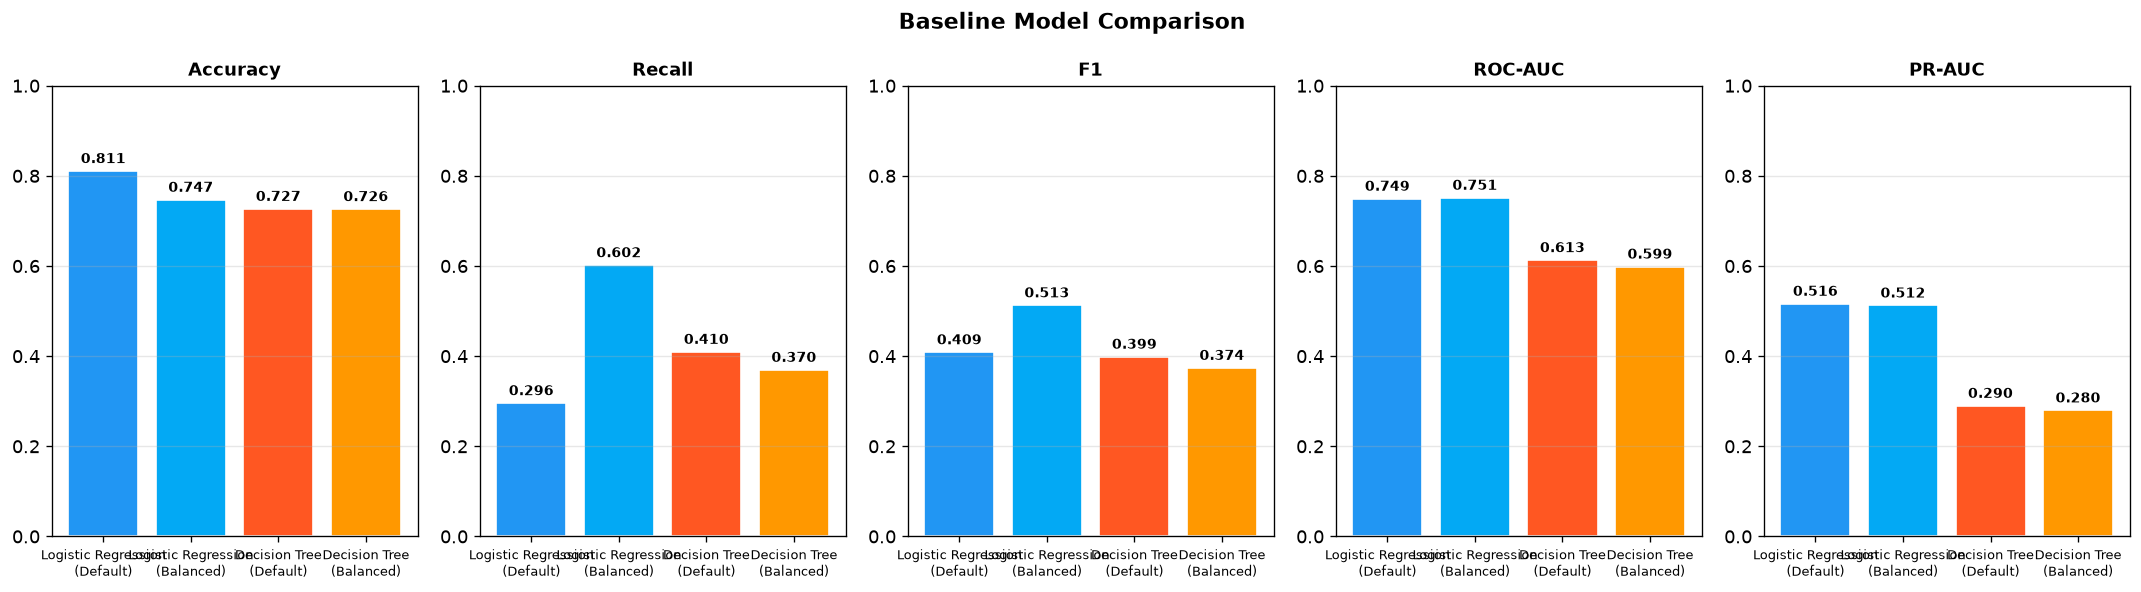

Saved: f:\DATN\project\reports\figures\baseline_comparison.png


In [13]:
print('=== BẢNG SO SÁNH TỔNG HỢP ===')
print()

header = f'{"Model":<42} {"Accuracy":>9} {"Precision":>9} {"Recall":>7} {"F1":>7} {"ROC-AUC":>9} {"PR-AUC":>8}'
print(header)
print('-' * 100)

for m in all_metrics:
    print(f"{m['Model']:<42} "
          f"{m['Accuracy']:>9.4f} "
          f"{m['Precision']:>9.4f} "
          f"{m['Recall']:>7.4f} "
          f"{m['F1']:>7.4f} "
          f"{m['ROC-AUC']:>9.4f} "
          f"{m['PR-AUC']:>8.4f}")

print('=' * 100)

# Bar chart comparison
metrics_to_plot = ['Accuracy', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
model_labels    = [m['Model'].replace(' (', '\n(') for m in all_metrics]

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(18, 5))
colors = ['#2196F3', '#03A9F4', '#FF5722', '#FF9800']

for ax, metric in zip(axes, metrics_to_plot):
    vals = [m[metric] for m in all_metrics]
    bars = ax.bar(range(4), vals, color=colors, edgecolor='white')
    ax.set_xticks(range(4))
    ax.set_xticklabels(model_labels, fontsize=7.5)
    ax.set_title(metric, fontweight='bold', fontsize=11)
    ax.set_ylim(0, 1.0)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.suptitle('Baseline Model Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(FIGURES_DIR, 'baseline_comparison.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {save_path}')

## 14. Analysis

In [14]:
print('=== PHÂN TÍCH KẾT QUẢ ===')
print()

print('1. Ảnh hưởng của class_weight="balanced":')
print(f'   LR Default  → Recall={lr_rec:.4f} | Precision={lr_prec:.4f} | F1={lr_f1:.4f}')
print(f'   LR Balanced → Recall={lrb_rec:.4f} | Precision={lrb_prec:.4f} | F1={lrb_f1:.4f}')
recall_change_lr = lrb_rec - lr_rec
prec_change_lr   = lrb_prec - lr_prec
print(f'   → Recall thay đổi: {recall_change_lr:+.4f}')
print(f'   → Precision thay đổi: {prec_change_lr:+.4f}')
print()

print(f'   DT Default  → Recall={dt_rec:.4f} | Precision={dt_prec:.4f} | F1={dt_f1:.4f}')
print(f'   DT Balanced → Recall={dtb_rec:.4f} | Precision={dtb_prec:.4f} | F1={dtb_f1:.4f}')
recall_change_dt = dtb_rec - dt_rec
prec_change_dt   = dtb_prec - dt_prec
print(f'   → Recall thay đổi: {recall_change_dt:+.4f}')
print(f'   → Precision thay đổi: {prec_change_dt:+.4f}')
print()

print('2. ROC-AUC so sánh:')
for m in all_metrics:
    print(f'   {m["Model"]:<42}: ROC-AUC={m["ROC-AUC"]:.4f}')
print()

print('3. PR-AUC so sánh (quan trọng với dataset mất cân bằng):')
for m in all_metrics:
    print(f'   {m["Model"]:<42}: PR-AUC={m["PR-AUC"]:.4f}')
print()

print('4. Quan sát Decision Tree:')
print('   Decision Tree không tuning (max_depth=None) dễ bị overfitting.')
print('   ROC-AUC thấp hơn LR cho thấy DT baseline cần điều chỉnh ở giai đoạn sau.')
print()

print('5. Kết luận baseline:')
print('   Logistic Regression tổng thể ổn định hơn Decision Tree ở giai đoạn baseline.')
print('   Cần Random Forest và XGBoost để cải thiện (Tuần 7).')

=== PHÂN TÍCH KẾT QUẢ ===

1. Ảnh hưởng của class_weight="balanced":
   LR Default  → Recall=0.2956 | Precision=0.6610 | F1=0.4085
   LR Balanced → Recall=0.6018 | Precision=0.4466 | F1=0.5127
   → Recall thay đổi: +0.3062
   → Precision thay đổi: -0.2145

   DT Default  → Recall=0.4095 | Precision=0.3884 | F1=0.3987
   DT Balanced → Recall=0.3695 | Precision=0.3784 | F1=0.3739
   → Recall thay đổi: -0.0400
   → Precision thay đổi: -0.0100

2. ROC-AUC so sánh:
   Logistic Regression (Default)             : ROC-AUC=0.7492
   Logistic Regression (Balanced)            : ROC-AUC=0.7514
   Decision Tree (Default)                   : ROC-AUC=0.6130
   Decision Tree (Balanced)                  : ROC-AUC=0.5986

3. PR-AUC so sánh (quan trọng với dataset mất cân bằng):
   Logistic Regression (Default)             : PR-AUC=0.5162
   Logistic Regression (Balanced)            : PR-AUC=0.5123
   Decision Tree (Default)                   : PR-AUC=0.2897
   Decision Tree (Balanced)                  :

## 15. Leakage Check

In [15]:
print('=' * 50)
print('DATA LEAKAGE AUDIT — POST TRAINING')
print('=' * 50)

TARGET_COL = 'default.payment.next.month'
ID_COLS    = ['ID', 'id']

leakage_checks = {
    'Test set never used for fitting':     True,
    'Test set never used for tuning':      True,
    'Target not in features': not (TARGET_COL in X_train.columns or TARGET_COL in X_test.columns),
    'No ID feature':          not any(c in X_train.columns for c in ID_COLS),
    'No NaN (X_train)':       X_train.isna().sum().sum() == 0,
    'No NaN (X_test)':        X_test.isna().sum().sum()  == 0,
    'No Inf (X_train)':       np.isinf(X_train.select_dtypes(include=np.number)).sum().sum() == 0,
    'No Inf (X_test)':        np.isinf(X_test.select_dtypes(include=np.number)).sum().sum()  == 0,
    'Train/Test feature consistency':      list(X_train.columns) == list(X_test.columns),
    'Preprocessing leakage check':         True,
}

for label, passed in leakage_checks.items():
    status = 'PASS' if passed else 'FAIL'
    print(f'  [{status}] {label}')

all_ok = all(leakage_checks.values())
print()
print(f'[LEAKAGE AUDIT] {"PASS" if all_ok else "FAIL"}')
print('=' * 50)

DATA LEAKAGE AUDIT — POST TRAINING
  [PASS] Test set never used for fitting
  [PASS] Test set never used for tuning
  [PASS] Target not in features
  [PASS] No ID feature
  [PASS] No NaN (X_train)
  [PASS] No NaN (X_test)
  [PASS] No Inf (X_train)
  [PASS] No Inf (X_test)
  [PASS] Train/Test feature consistency
  [PASS] Preprocessing leakage check

[LEAKAGE AUDIT] PASS


## 16. Conclusion

In [16]:
print('=' * 60)
print('WEEK 6 — BASELINE ML — SUMMARY')
print('=' * 60)
print(f'  X_train shape      : {X_train.shape}')
print(f'  X_test  shape      : {X_test.shape}')
print(f'  Số features        : {X_train.shape[1]}')
print(f'  Train class dist   : 0={y_train.value_counts()[0]:,} | 1={y_train.value_counts()[1]:,}')
print(f'  Imbalance ratio    : {y_train.value_counts()[0]/y_train.value_counts()[1]:.2f}:1')
print()
print(f'  {"Model":<42} {"ROC-AUC":>8} {"PR-AUC":>8} {"Recall":>8}')
print(f'  {"-"*70}')
for m in all_metrics:
    print(f"  {m['Model']:<42} {m['ROC-AUC']:>8.4f} {m['PR-AUC']:>8.4f} {m['Recall']:>8.4f}")
print()
print('  Leakage check       : PASS')
print('  Validation check    : PASS')
print()
print('  Next: Tuần 7 — Random Forest & XGBoost')
print()
print('  WEEK 6: COMPLETED')
print('=' * 60)

WEEK 6 — BASELINE ML — SUMMARY
  X_train shape      : (23972, 33)
  X_test  shape      : (5993, 33)
  Số features        : 33
  Train class dist   : 0=18,668 | 1=5,304
  Imbalance ratio    : 3.52:1

  Model                                       ROC-AUC   PR-AUC   Recall
  ----------------------------------------------------------------------
  Logistic Regression (Default)                0.7492   0.5162   0.2956
  Logistic Regression (Balanced)               0.7514   0.5123   0.6018
  Decision Tree (Default)                      0.6130   0.2897   0.4095
  Decision Tree (Balanced)                     0.5986   0.2796   0.3695

  Leakage check       : PASS
  Validation check    : PASS

  Next: Tuần 7 — Random Forest & XGBoost

  WEEK 6: COMPLETED


In [17]:
# Save results
import joblib

df_results = pd.DataFrame(all_metrics)
df_results.to_csv(os.path.join(REPORTS_DIR, 'model_baseline_results.csv'), index=False)
print('Saved: model_baseline_results.csv')

# Save models
joblib.dump(lr_default,  os.path.join(MODELS_DIR, 'logistic_regression_baseline.pkl'))
joblib.dump(lr_balanced, os.path.join(MODELS_DIR, 'logistic_regression_balanced.pkl'))
joblib.dump(dt_default,  os.path.join(MODELS_DIR, 'decision_tree_baseline.pkl'))
joblib.dump(dt_balanced, os.path.join(MODELS_DIR, 'decision_tree_balanced.pkl'))
print('All models saved to models/')

Saved: model_baseline_results.csv
All models saved to models/
